In [96]:
# Importing important libraries

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [176]:
# Importing the data set

dataset = pd.read_csv('F:\ML Projects\Machine Learning Projects\DataFiles\car data.csv')


In [177]:
dataset.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [178]:
# Basic info of the dataset

dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [179]:
# from the above we can see that there are no missig values in the dataset

dataset.isnull().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

In [180]:
# checking the basic statistics of the data

dataset.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,301.0,2013.627907,2.891554,2003.00,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,4.661296,5.082812,0.10,0.9,3.6,6.0,35.0
Present_Price,301.0,7.628472,8.644115,0.32,1.2,6.4,9.9,92.6
Kms_Driven,301.0,36947.205980,38886.883882,500.00,15000.0,32000.0,48767.0,500000.0
Owner,301.0,0.043189,0.247915,0.00,0.0,0.0,0.0,3.0


In [181]:
# there are lot of categorical values need to be encoded by label encoding or ordinal encoding...

dataset.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [183]:
dataset['Fuel_Type'].value_counts()

Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64

In [185]:
dataset['Fuel_Type'] = dataset['Fuel_Type'].replace({'Diesel':0,'Petrol':1,'CNG':2,'LPG':3,'Electric':4})

In [105]:
dataset['fuel'].value_counts()

fuel
0    2153
1    2123
2      40
3      23
4       1
Name: count, dtype: int64

In [188]:
dataset['Seller_Type'].value_counts()

Seller_Type
Dealer        195
Individual    106
Name: count, dtype: int64

In [189]:
dataset['Seller_Type'] = dataset['Seller_Type'].replace({'Individual':0,'Dealer':1,'Trustmark Dealer':2})

In [190]:
dataset['Seller_Type'].value_counts()

Seller_Type
1    195
0    106
Name: count, dtype: int64

In [191]:
dataset['Transmission'].value_counts()

Transmission
Manual       261
Automatic     40
Name: count, dtype: int64

In [192]:
dataset['Transmission'] = dataset['Transmission'].replace({'Manual':0,'Automatic':1})

In [194]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    int64  
 6   Seller_Type    301 non-null    int64  
 7   Transmission   301 non-null    int64  
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 21.3+ KB


In [116]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   int64 
 5   seller_type    4340 non-null   int64 
 6   transmission   4340 non-null   int64 
 7   owner          4340 non-null   int64 
dtypes: int64(7), object(1)
memory usage: 271.4+ KB


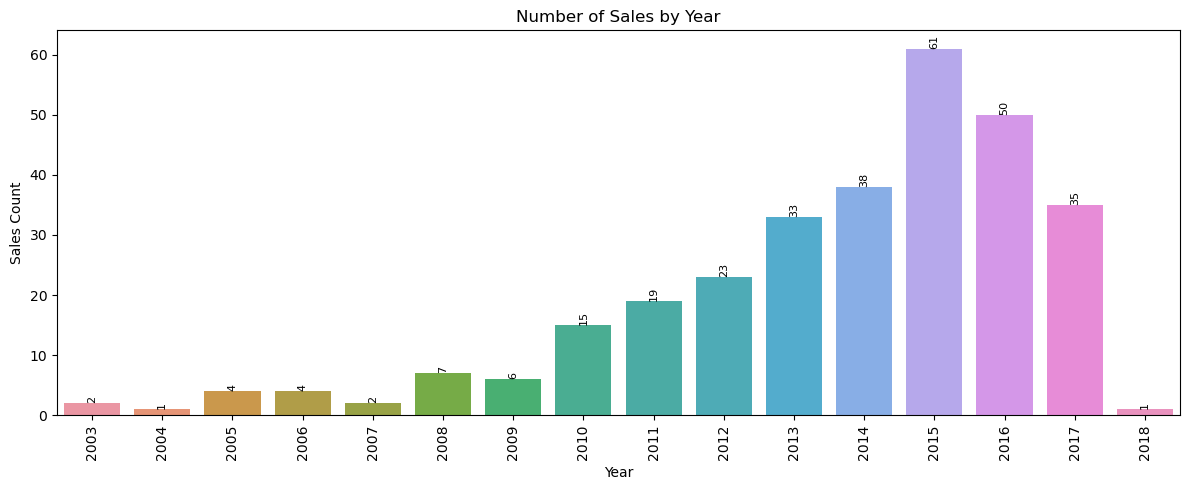

In [197]:
import matplotlib.pyplot as plt
import seaborn as sns

sales_count = dataset['Year'].value_counts().sort_index()

plt.figure(figsize=(12,5))
ax = sns.barplot(
    x=sales_count.index,
    y=sales_count.values
)

plt.xticks(rotation=90)
plt.title("Number of Sales by Year")
plt.ylabel("Sales Count")

# 🔹 Add labels on bars
for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha='center',
        va='bottom',
        fontsize=8,
        rotation=90
    )

plt.tight_layout()
plt.show()

In [119]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   int64 
 5   seller_type    4340 non-null   int64 
 6   transmission   4340 non-null   int64 
 7   owner          4340 non-null   int64 
dtypes: int64(7), object(1)
memory usage: 271.4+ KB


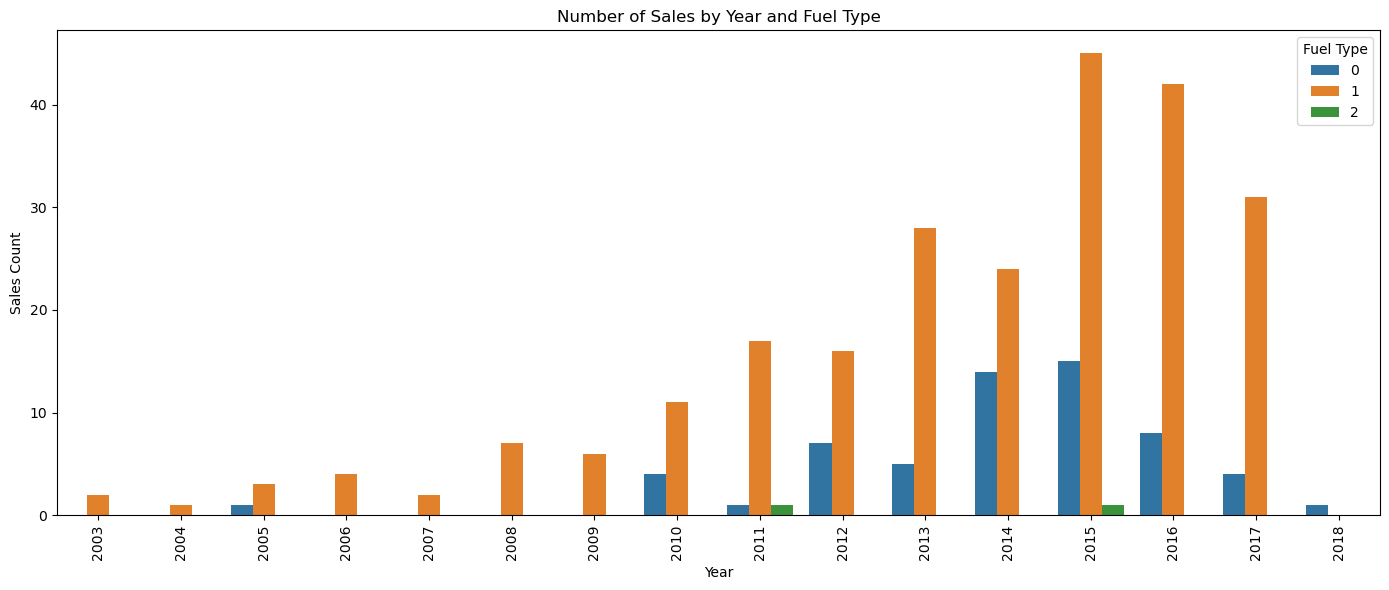

In [198]:
plt.figure(figsize=(14,6))
sns.countplot(
    data=dataset,
    x='Year',
    hue='Fuel_Type'
)
plt.xticks(rotation=90)
plt.title("Number of Sales by Year and Fuel Type")
plt.xlabel("Year")
plt.ylabel("Sales Count")
plt.legend(title="Fuel Type")
plt.tight_layout()
plt.show()

# 'Diesel':0,'Petrol':1,'CNG':2,'LPG':3,'Electric':4

# Observations.

# There are more sales for diesel type vechiles past from one decade.

In [200]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    int64  
 6   Seller_Type    301 non-null    int64  
 7   Transmission   301 non-null    int64  
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 21.3+ KB


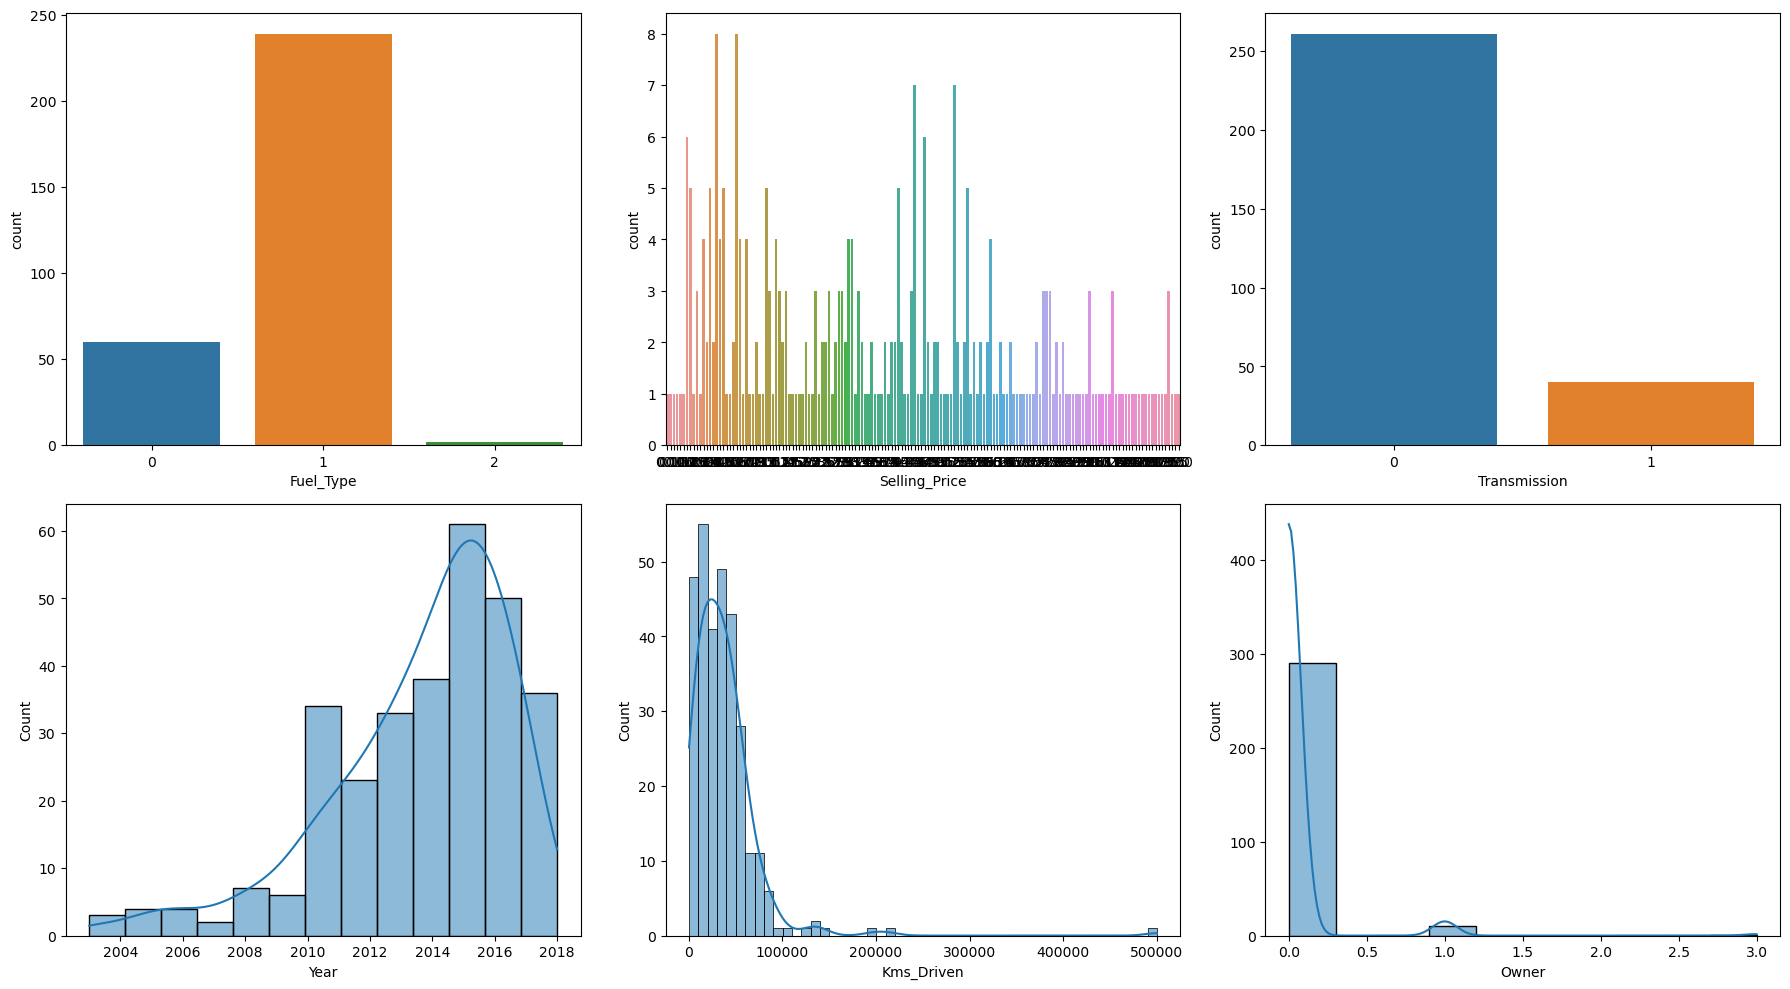

In [202]:
fig, axes = plt.subplots(2, 3, figsize=(18,10))

sns.countplot(data=dataset, x='Fuel_Type', ax=axes[0,0])
sns.countplot(data=dataset, x='Selling_Price', ax=axes[0,1])
sns.countplot(data=dataset, x='Transmission', ax=axes[0,2])

sns.histplot(dataset['Year'], kde=True, ax=axes[1,0])
sns.histplot(dataset['Kms_Driven'], kde=True, ax=axes[1,1])
sns.histplot(dataset['Owner'], kde=True, ax=axes[1,2])

plt.tight_layout()
plt.show()


# more demand for fuel type will be disel and petrol.
# more demand seller type 0 ,1
# more demand for transmission is manual
# more kms driven 60 k + 
# single owner will be more demand. 

In [ ]:
# dividing the data set into independent and dependent varibles
  
X = dataset.drop(['Car_Name', 'Selling_Price'], axis=1)
y = dataset['Selling_Price']

In [204]:
X.head()

,Year,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,2014,5.59,27000,1,1,0,0
1,2013,9.54,43000,0,1,0,0
2,2017,9.85,6900,1,1,0,0
3,2011,4.15,5200,1,1,0,0
4,2014,6.87,42450,0,1,0,0


In [205]:
print('hello')

hello


In [206]:
# dividing the data set into train test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=321)

In [207]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((240, 7), (61, 7), (240,), (61,))

In [208]:
# dividing the data set into train test split

from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)


In [209]:
X_train.shape

(240, 7)

In [210]:
# Importing all the regression models.

from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

In [211]:
models = {'LR': LinearRegression(),
          'SVR' : SVR(),
          'DT': DecisionTreeRegressor(),
          'KNN': KNeighborsRegressor(),
          'RFR':RandomForestRegressor(),
          'Lasso': Lasso(),
          'ridge':Ridge()
          }

In [223]:
# Training Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def evaulation_train_model(X_train_predict,y_train):

    X_train_predict = np.array(X_train_predict)
    X_train = np.array(y_train)

    MAE_T = mean_absolute_error(X_train_predict,y_train)
    MSE_T = mean_squared_error(X_train_predict,y_train)
    R2_T= r2_score(X_train_predict,y_train)

    return MAE_T,MSE_T,R2_T


In [227]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "R2" : r2_score(y_true, y_pred)
    }


In [228]:
model_names = []
train_r2 = []
test_r2 = []

for model_name, model in models.items():

    # Train
    model.fit(X_train_scaled, y_train)

    # Predictions
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred  = model.predict(X_test_scaled)

    # Evaluation
    train_metrics = evaluate(y_train, y_train_pred)
    test_metrics  = evaluate(y_test, y_test_pred)

    # Store
    model_names.append(model_name)
    train_r2.append(train_metrics["R2"])
    test_r2.append(test_metrics["R2"])

    # Print
    print(model_name)
    print("Train Performance")
    print(train_metrics)

    print("Test Performance")
    print(test_metrics)
    print("=" * 40)


LR
Train Performance
{'MAE': 1.2347160720409236, 'MSE': 3.2681473300655886, 'R2': 0.8756731670252524}
Test Performance
{'MAE': 1.0325537729913898, 'MSE': 2.16488374188795, 'R2': 0.9064152674569327}
SVR
Train Performance
{'MAE': 1.1313425327690083, 'MSE': 9.463438735042708, 'R2': 0.6399919440122674}
Test Performance
{'MAE': 0.8863100910722949, 'MSE': 5.1735550066570655, 'R2': 0.7763548442686269}
DT
Train Performance
{'MAE': 0.0, 'MSE': 0.0, 'R2': 1.0}
Test Performance
{'MAE': 0.47393442622950827, 'MSE': 0.5753918032786887, 'R2': 0.9751266606259652}
KNN
Train Performance
{'MAE': 0.7878916666666667, 'MSE': 2.22368915, 'R2': 0.9154064362409696}
Test Performance
{'MAE': 0.6768852459016393, 'MSE': 0.9100955409836067, 'R2': 0.9606579114879799}
RFR
Train Performance
{'MAE': 0.26963750000000003, 'MSE': 0.4352755556666665, 'R2': 0.9834412510080217}
Test Performance
{'MAE': 0.4357868852459018, 'MSE': 0.5240330052459017, 'R2': 0.9773468257482919}
Lasso
Train Performance
{'MAE': 1.6733310785829707,

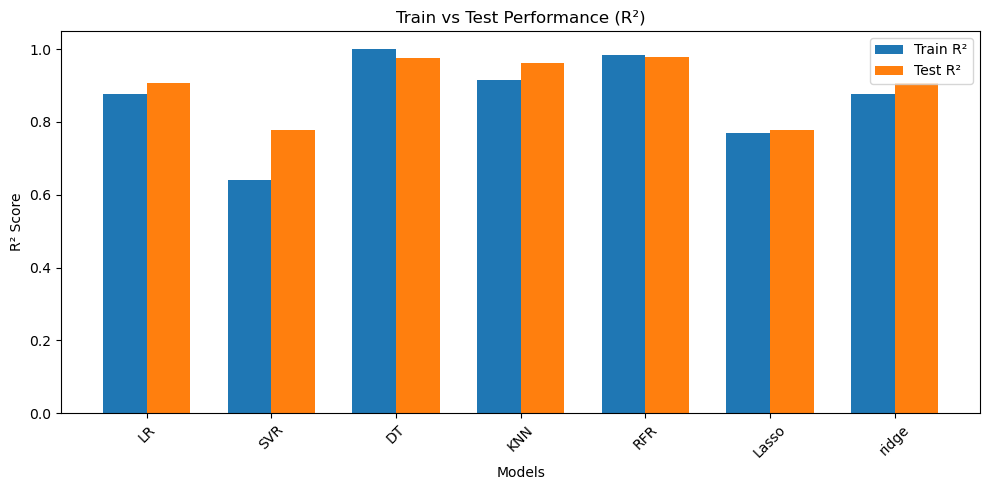

In [230]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(model_names))   # model positions
width = 0.35                      # bar width

plt.figure(figsize=(10,5))

plt.bar(x - width/2, train_r2, width, label='Train R²')
plt.bar(x + width/2, test_r2,  width, label='Test R²')

plt.xlabel("Models")
plt.ylabel("R² Score")
plt.title("Train vs Test Performance (R²)")
plt.xticks(x, model_names, rotation=45)
plt.legend()

plt.tight_layout()
plt.show()



In [231]:
import pandas as pd

results = []

for model_name, model in models.items():

    # Train
    model.fit(X_train_scaled, y_train)

    # Predictions
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred  = model.predict(X_test_scaled)

    # Evaluation
    train_metrics = evaluate(y_train, y_train_pred)
    test_metrics  = evaluate(y_test, y_test_pred)

    # Store results
    results.append({
        "Model": model_name,

        "Train_R2": train_metrics["R2"],
        "Test_R2":  test_metrics["R2"],

        "Train_MAE": train_metrics["MAE"],
        "Test_MAE":  test_metrics["MAE"],

        "Train_MSE": train_metrics["MSE"],
        "Test_MSE":  test_metrics["MSE"]
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Sort by Test R2 (best model on top)
results_df = results_df.sort_values(by="Test_R2", ascending=False)

results_df


,Model,Train_R2,Test_R2,Train_MAE,Test_MAE,Train_MSE,Test_MSE
4,RFR,0.982751,0.981109,0.271264,0.405680,0.453428,0.437005
2,DT,1.000000,0.973524,0.000000,0.462131,0.000000,0.612474
3,KNN,0.915406,0.960658,0.787892,0.676885,2.223689,0.910096
0,LR,0.875673,0.906415,1.234716,1.032554,3.268147,2.164884
6,ridge,0.875659,0.905981,1.234931,1.031972,3.268517,2.174936
5,Lasso,0.768566,0.777185,1.673331,1.495631,6.083646,5.154343
1,SVR,0.639992,0.776355,1.131343,0.886310,9.463439,5.173555
